In [1]:
%pylab inline

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


In [2]:
import glob
from ISRpy import beampack

jro0 = beampack.jrobeam

from IPython import display
import numpy as np

In [3]:
from OXmodeCython import OXmode_cython

In [4]:
dz=0.5 # resolution in km --- 0.1 is for good resolution, 0.5 for speed
zmax = 800
Z = np.arange(0.01,zmax,dz)

In [5]:
def fps_parabolic(a,z,beta=7):
    def softplus(x):
        return 1/beta*np.log(1+np.exp(x*beta))
    para1 = a[0]-((z-a[1])/a[2]/3)**2
    para2 = a[3]-((z-a[4])/a[5]/3)**2
    para3 = a[6]-((z-a[7])/a[8]/3)**2

    fps1 = (80.6*(softplus(para1) + softplus(para2) + softplus(para3)))**0.5
    # fps2 = (80.6*np.max(np.vstack([para1,para2,para3]), axis=0))**0.5
    return fps1#,fps2


In [6]:
from matplotlib import pyplot as plt
from matplotlib import rcParams
import scipy.interpolate as inter
import numpy as np
import datetime
import scipy.constants as const
import time


def graph_generate(params):
    try:
        ppparam, fes, dz = params
        rcParams['figure.subplot.right'] = 0.78
        fig,axes = plt.subplots(1,1,figsize=(10.0,8.0),sharex=True)
        ax1 = axes
        fps=fps_parabolic(ppparam, Z)
        ax1.plot(fps,Z)
        fvsO,vhsO,fvsX,vhsX=OXmode_cython(fps,fes,dz) # x1 y1 x2 y2 

        def scatter_around_points(x_data : np.ndarray, y_data : np.ndarray, points=20):
            noisy_x = x_data.tolist()
            noisy_y = y_data.tolist()
            sigma_x = abs(x_data[1] - x_data[0])
            sigma_y = abs(y_data[1] - y_data[0])
            for idx in range(x_data.shape[0]):
                if idx < x_data.shape[0]-1: 
                    sigma_x = abs(x_data[idx+1] - x_data[idx])
                    sigma_y = abs(y_data[idx+1] - y_data[idx])
                    if sigma_y > 100:
                        num_points = int(points*sigma_y/15)
                        for _ in range(num_points):
                            dx = np.random.normal(0, sigma_x/2)
                            dy = np.random.normal(0, min(sigma_y,50))
                            noisy_x.append(x_data[idx] + dx)
                            noisy_y.append(y_data[idx] + sigma_y/2 + dy)
                for _ in range(points):
                    dx = np.random.normal(0, sigma_x/2)
                    dy = np.random.normal(0, min(sigma_y,10))
                    noisy_x.append(x_data[idx] + dx)
                    noisy_y.append(y_data[idx] + dy)

            return np.array(noisy_x), np.array(noisy_y)

        # Generate noisy data
        fvsO_noisy_x, vhsO_noisy_y = scatter_around_points(fvsO, vhsO)
        fvsX_noisy_x, vhsX_noisy_y = scatter_around_points(fvsX, vhsX)

        # Generate random illumination values for each point
        illumination_O = np.random.rand(len(fvsO_noisy_x))
        illumination_X = np.random.rand(len(fvsX_noisy_x))

        sizes_O = np.random.normal(0.1, 0.5, len(fvsO_noisy_x))  # Random sizes between 1 and 50 for O-trace
        sizes_X = np.random.normal(0.1, 0.5, len(fvsX_noisy_x))  # Random sizes between 1 and 50 for X-trace

        # Scatter the noisy data with random illumination
        scatter_O = ax1.scatter(fvsO_noisy_x, vhsO_noisy_y, c=illumination_O, cmap='gray', s=sizes_O, label='O-trace hv')
        scatter_X = ax1.scatter(fvsX_noisy_x, vhsX_noisy_y, c=illumination_X, cmap='gray', s=sizes_X, label='X-trace hv')

        ax1.set_axis_off()

        x_min, x_max = (0,12)
        y_min, y_max = (0,800)
        ax1.set_xlim(x_min, x_max)
        ax1.set_ylim(y_min, y_max)
#         print(xvals)
        file_name = "_".join([f"{x:.5f}" for x in ppparam]) + "_.png"
        fig.savefig(f"training_data_parabola/train/{file_name}", dpi=100, bbox_inches='tight', pad_inches=0, facecolor=fig.get_facecolor())
        plt.show()
        
        fig,axe = plt.subplots(1,1,figsize=(10.0,8.0),sharex=True)
        axe.set_axis_off()
        axe.set_xlim(x_min, x_max)
        axe.set_ylim(y_min, y_max)
        scatter_O = axe.scatter(fvsO_noisy_x, vhsO_noisy_y, c='b', s=sizes_O, label='O-trace hv')
        file_name = "_".join([f"{x:.5f}" for x in ppparam]) + "_.png"
        fig.savefig(f"training_data_parabola/O/{file_name}", dpi=100, bbox_inches='tight', pad_inches=0, facecolor=fig.get_facecolor())
        plt.show()
        
        fig,axe = plt.subplots(1,1,figsize=(10.0,8.0),sharex=True)
        axe.set_axis_off()
        axe.set_xlim(x_min, x_max)
        axe.set_ylim(y_min, y_max)
        scatter_X = axe.scatter(fvsX_noisy_x, vhsX_noisy_y, c='r', s=sizes_X, label='X-trace hv')
        file_name = "_".join([f"{x:.5f}" for x in ppparam]) + "_.png"
        fig.savefig(f"training_data_parabola/X/{file_name}", dpi=100, bbox_inches='tight', pad_inches=0, facecolor=fig.get_facecolor())
        plt.show()
    except:
        # print(e)
        pass



/home/linle2/.local/lib/python3.11/site-packages/matplotlib/collections.py:996: RuntimeWarning: invalid value encountered in sqrt
  scale = np.sqrt(self._sizes) * dpi / 72.0 * self._factor


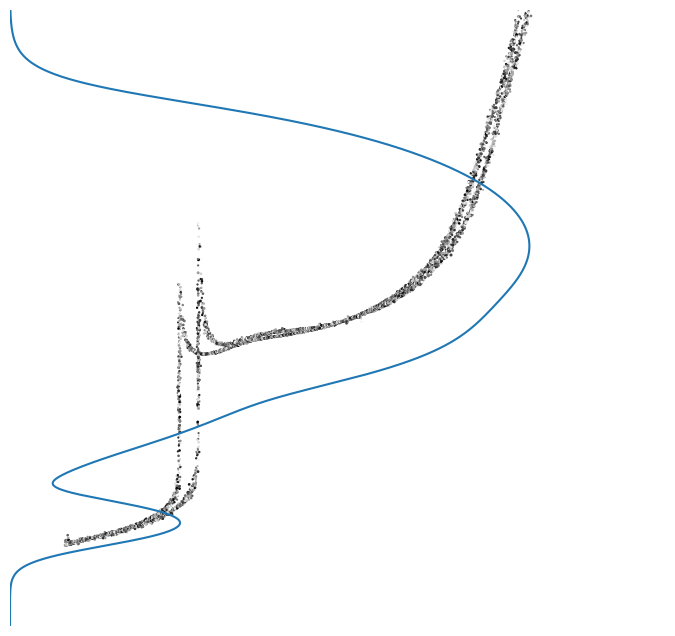

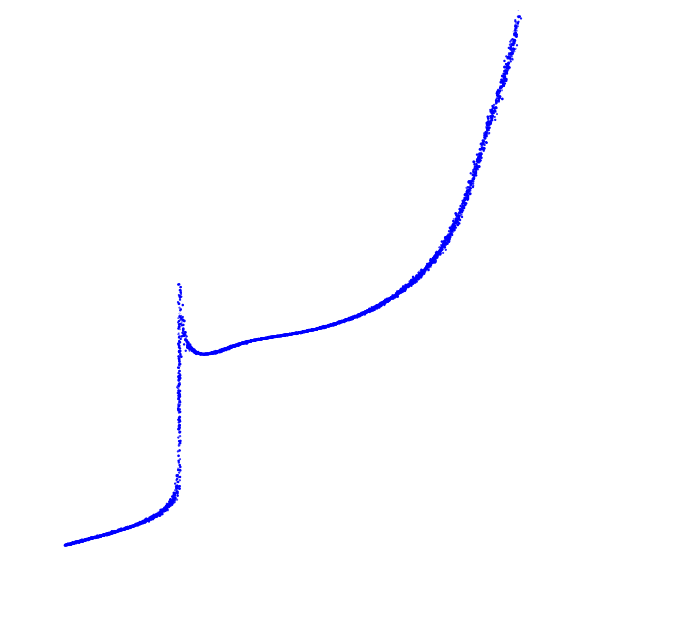

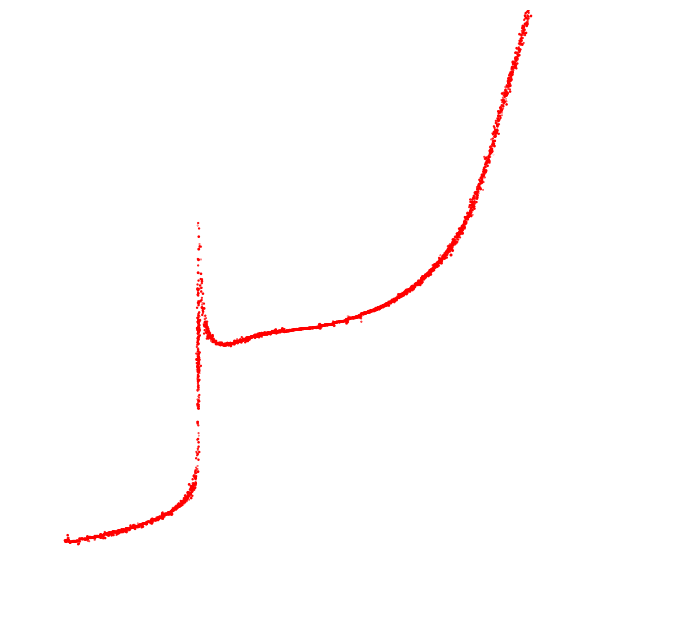

In [7]:
import random
dt0 = datetime.datetime(2015,4,15)
igrf_year = dt0.year + (dt0-datetime.datetime(dt0.year,1,1)).total_seconds() / (
        datetime.datetime(dt0.year+1,1,1)-datetime.datetime(dt0.year,1,1)).total_seconds()
dz=0.5 # resolution in km --- 0.1 is for good resolution, 0.5 for speed
zmax = 800
Z = np.arange(0.01,zmax,dz)
fes = []
for iZ in Z:
    r,geoc_lat,lon,aspect,B = jro0.aspect_angle(igrf_year,jro0.xyz0 + jro0.zenith0 * iZ)
    fes += [const.e * np.linalg.norm(B) * 1e-9 / const.m_e /1e6 /2/np.pi] #MHz
fes = np.array(fes)
param = [random.uniform(0.75, 1.25) * 0.9,
         random.uniform(300, 500),
         random.uniform(0.75, 1.25) * 60,  
         random.uniform(0.75, 1.25) * 0.2,  
         random.uniform(220,320),
         random.uniform(0.75, 1.25) * 70,
         random.uniform(0.75, 1.25) * 0.04,
         random.uniform(130,170),
         random.uniform(0.75, 1.25) * 20] 
# print(param, len(param))
graph_generate((param,fes,dz))

In [8]:
from joblib import Parallel, delayed
import random 
import os
import multiprocessing as mp
from multiprocessing import Pool

# Generate parameters for the images [0.9,400,40,0.5,300,40,0.1,150,40]
parameters = []
for i in range(30000):  # Adjusted to generate 1000 sets of paramete
    igrf_year = dt0.year + (dt0-datetime.datetime(dt0.year,1,1)).total_seconds() / (datetime.datetime(dt0.year+1,1,1)-datetime.datetime(dt0.year,1,1)).total_seconds()
    param = [random.uniform(0.75, 1.25) * 0.9,
         random.uniform(300, 500),
         random.uniform(0.75, 1.25) * 60,  
         random.uniform(0.75, 1.25) * 0.2,  
         random.uniform(220,320),
         random.uniform(0.75, 1.25) * 70,
         random.uniform(0.75, 1.25) * 0.04,
         random.uniform(130,170),
         random.uniform(0.75, 1.25) * 20] 
    parameters += [(param,fes,dz)]

# Use all available CPU cores to generate the graphs in parallel
Parallel(n_jobs=mp.cpu_count()-8)(delayed(graph_generate)(p) for p in parameters)
# processes_pool = Pool(20)
# processes_pool.map(graph_generate, parameters)
# processes_pool.close()
# elapsed_time = time.time() - start_time
# print(f'Generated 1000 images. Time elapsed: {elapsed_time:.2f} seconds')



ModuleNotFoundError: No module named 'joblib'

In [ ]:

dt0 = datetime.datetime(2015,4,15)
igrf_year = dt0.year + (dt0-datetime.datetime(dt0.year,1,1)).total_seconds() / (
        datetime.datetime(dt0.year+1,1,1)-datetime.datetime(dt0.year,1,1)).total_seconds()

dz=0.5 # resolution in km --- 0.1 is for good resolution, 0.5 for speed
zmin = 0
zmax = 800

rcParams['figure.subplot.right'] = 0.78
#set up a plot
fig,axes = plt.subplots(1,1,figsize=(9.0,8.0),sharex=True)
ax1 = axes

# height grid
Z = np.arange(0.01,zmax,dz)

# fps=fps_gauss(np.array([0.9,380,22,0.2,150,10]),Z)
# m, = ax1.plot (fps, Z, 'k-', label='spline fp')

fps1, fps2=fps_parabolic(np.array([0.9,400,40,0.5,300,40,0.1,150,40]),Z)
m, = ax1.plot (fps1, Z, 'r-', label='spline fp')
m, = ax1.plot (fps2, Z, 'b-', label='spline fp')

# start = time.time()
# fvsO,vhsO,fvsX,vhsX=OXmode_cython(fps,fes,dz)
# mO, = ax1.plot (fvsO, vhsO, 'g-', label='O-trace hv')
# mX, = ax1.plot (fvsX, vhsX, 'y-', label='X-trace hv')
# print('new oxmode:',time.time() - start)

# ax1.set_yscale('linear')
# ax1.set_xlim(0,12)
# ax1.set_ylim(0,zmax)
# ax1.set_xlabel('fp, fv (MHz)')
# ax1.set_ylabel('z, hv (km)')
# ax1.grid(True)
# ax1.yaxis.grid(True,which='minor',linestyle='--')
# ax1.legend(loc=2,prop={'size':11})
